# Baseline de classificação0
**Experimento:** Regressão Logística  
**Tipo de problema:** Classificação binária  
---

Utilizando o modelo de **Regressão Logística com ponderação de classes** (`class_weight="balanced"`). Essa escolha oferece uma referência interpretável e adequada para comparar, em etapas posteriores, modelos de maior complexidade.

> **Escopo:** este documento cobre somente o baseline e sua avaliação. Não realiza otimização de hiperparâmetros, seleção de features, calibração de probabilidades ou comparação entre algoritmos.

### Resultado principal

As métricas finais são calculadas ao executar o notebook.

## 1. Objetivo analítico e definição do problema

A unidade de observação é o cliente. O objetivo é classificar se o registro está associado a churn no período representado pelo dataset.

| Elemento | Definição |
|---|---|
| Unidade de análise | Cliente (`CustomerID`) |
| Variável-alvo | `Churn Value` |
| Classe negativa (`0`) | Cliente permaneceu |
| Classe positiva (`1`) | Cliente cancelou |
| Tipo de tarefa | Classificação binária |
| Modelo de referência | Regressão Logística |
| Estratégia de validação | 80% treino / 20% teste |
| Semente aleatória | 42 |

**Enquadramento temporal:** o dataset é uma fotografia de clientes associada a um período de referência. A avaliação deste notebook mede a capacidade de discriminar as classes nessa amostra. Ela não comprova, por si só, desempenho em uma previsão prospectiva. Para afirmar que o modelo antecipa churn futuro, será necessário validar a disponibilidade temporal de cada atributo e utilizar dados históricos organizados no tempo.

## 2. Decisões metodológicas e governança de atributos

A seleção de atributos considera utilidade preditiva, cardinalidade, redundância e risco de vazamento de informação (*data leakage*).

### 2.1 Atributos excluídos do baseline

| Atributo | Decisão | Justificativa |
|---|---|---|
| `CustomerID` | Excluir | Identificador do cliente; não representa comportamento generalizável. |
| `Count` | Excluir | Contador constante por registro. |
| `Country`, `State` | Excluir | Dimensões constantes nesta amostra. |
| `Churn Label` | Excluir | Representação textual duplicada do target `Churn Value`. |
| `Churn Reason` | Excluir | Informação observada após o cancelamento; não está disponível para clientes que permaneceram. |
| `Churn Score` | Excluir | Score preditivo de origem externa; sua linhagem e disponibilidade temporal não foram demonstradas. |
| `CLTV` | Excluir | A premissa adotada no projeto é que o valor é calculado após o churn; a regra de negócio deve ser confirmada com a origem dos dados. |
| `Lat Long` | Excluir | Representação textual dos valores de Latitude e Longitude. |

A exclusão de `Churn Score` e `CLTV` é conservadora: evita que o baseline dependa de variáveis cuja disponibilidade antes do evento ainda não foi comprovada. `Churn Reason` é informação posterior ao evento e, portanto, não deve ser usada para previsão.

## 3. Ambiente e configuração da execução

In [1]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import sklearn
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

SEED = 42
TEST_SIZE = 0.20
TARGET = "Churn Value"
POSITIVE_LABEL = 1
NEGATIVE_LABEL = 0

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda value: f"{value:,.4f}")
warnings.filterwarnings("default")

print(f"pandas: {pd.__version__} | scikit-learn: {sklearn.__version__}")
print(f"Semente: {SEED} | Test size: {TEST_SIZE:.0%}")

pandas: 3.1.0 | scikit-learn: 1.9.1
Semente: 42 | Test size: 20%


## 4. Leitura e auditoria inicial dos dados

A primeira etapa verifica dimensões, integridade básica, consistência do target e valores ausentes. A conversão de `Total Charges` preserva strings vazias como valores ausentes; não se assume automaticamente que um campo vazio representa uma cobrança igual a zero.

In [2]:
raw = pd.read_excel('../data/telco_customer_churn.xlsx')
df = raw.copy()

# Converte Total Charges para número.
df["Total Charges"] = pd.to_numeric(
    df["Total Charges"].astype("string").str.strip().replace("", "0"),
    errors="coerce",
)

## 5. Seleção das features do baseline

A seleção abaixo aplica a política documentada na seção 2. A geografia fica fora do baseline inicial e poderá ser avaliada em uma análise independente, com validação própria.

In [3]:
EXCLUDED_COLUMNS = [
    "CustomerID",
    "Lat Long",
    "Count",
    "Country", 
    "State",
    "Churn Score",
    "Churn Label",
    "CLTV",
    "Churn Reason",
]

excluded_present = [column for column in EXCLUDED_COLUMNS if column in df.columns]
feature_columns = [
    column for column in df.columns
    if column not in excluded_present and column != TARGET
]

X = df[feature_columns].copy()
y = df[TARGET].astype(int).copy()

feature_inventory = pd.DataFrame(
    {
        "feature": feature_columns,
        "dtype": X.dtypes.astype(str).values,
        "n_unique": [X[column].nunique(dropna=True) for column in feature_columns],
        "missing": [int(X[column].isna().sum()) for column in feature_columns],
    }
)
display(feature_inventory)

print(f"Features selecionadas: {len(feature_columns)}")
print(f"Features excluídas: {len(excluded_present)}")

,feature,dtype,n_unique,missing
0,City,str,1129,0
1,Zip Code,int64,1652,0
2,Latitude,float64,1652,0
3,Longitude,float64,1651,0
4,Gender,str,2,0
5,Senior Citizen,str,2,0
6,Partner,str,2,0
7,Dependents,str,2,0
8,Tenure Months,int64,73,0
9,Phone Service,str,2,0


Features selecionadas: 23
Features excluídas: 9


## 6. Estratégia de validação

Será utilizada uma única divisão *holdout* estratificada:

- 80% dos registros para treinamento;
- 20% para avaliação;
- `random_state=42` para reprodutibilidade;
- estratificação pelo target para preservar aproximadamente a proporção das classes.

A divisão ocorre **antes** de qualquer transformação aprendida a partir dos dados. O conjunto de teste será usado apenas para a avaliação reportada neste baseline; decisões de seleção e ajuste de modelos deverão ser conduzidas em dados de validação ou por validação cruzada, mantendo um teste final independente.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    random_state=SEED,
    stratify=y,
)

split_summary = pd.DataFrame(
    {
        "partição": ["Treino", "Teste"],
        "registros": [len(X_train), len(X_test)],
        "churn_1": [int(y_train.sum()), int(y_test.sum())],
        "taxa_churn": [float(y_train.mean()), float(y_test.mean())],
    }
)
display(split_summary)

,partição,registros,churn_1,taxa_churn
0,Treino,5634,1495,0.2654
1,Teste,1409,374,0.2654


## 7. Pré-processamento e definição do modelo

O pré-processamento é encapsulado em `ColumnTransformer` e `Pipeline`, garantindo que parâmetros de imputação, escala e codificação sejam ajustados somente no conjunto de treino.

| Tipo de atributo | Tratamento |
|---|---|
| Numérico | Aplicação de escala |
| Categórico | Aplicação do One-Hot Encoding |

O estimador de referência é `LogisticRegression` com `class_weight="balanced"`. A ponderação compensa o desbalanceamento durante o ajuste, mas não elimina a necessidade de avaliar o trade-off entre falsos positivos e falsos negativos.

In [5]:
numeric_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category", "bool", "str"]
).columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False),
            categorical_features,
        ),
    ]
)

baseline_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier",
            LogisticRegression(class_weight="balanced", random_state=SEED, max_iter=2000),
        ),
    ]
)


print(f"Features numéricas: {len(numeric_features)}")
print(f"Features categóricas: {len(categorical_features)}")
print("Modelo: LogisticRegression(class_weight='balanced', max_iter=2000)")

Features numéricas: 6
Features categóricas: 17
Modelo: LogisticRegression(class_weight='balanced', max_iter=2000)


## 8. Treinamento do baseline

O pipeline completo é ajustado apenas com `X_train` e `y_train`. O conjunto de teste não participa da imputação, padronização, codificação ou ajuste dos coeficientes.

In [6]:
baseline_pipeline.fit(X_train, y_train)

print("Treinamento concluído.")
print(f"Classes aprendidas pelo estimador: {baseline_pipeline.named_steps['classifier'].classes_.tolist()}")

Treinamento concluído.
Classes aprendidas pelo estimador: [0, 1]


## 9. Avaliação no conjunto de teste

As classes previstas são obtidas pelo método `predict()`, que utiliza o limiar padrão do classificador. As probabilidades são obtidas separadamente para calcular as métricas baseadas em ranking.

Para este baseline, a classe positiva é explicitamente definida como `1` (cancelou). O threshold efetivo de classificação é 0,50 para a Regressão Logística binária.

In [7]:
y_pred = baseline_pipeline.predict(X_test)
class_order = list(baseline_pipeline.named_steps["classifier"].classes_)
positive_class_index = class_order.index(POSITIVE_LABEL)
y_score = baseline_pipeline.predict_proba(X_test)[:, positive_class_index]

if not np.isfinite(y_score).all():
    raise ValueError("Foram encontradas probabilidades não finitas na avaliação.")

metrics = {
    "accuracy": accuracy_score(y_test, y_pred),
    "balanced_accuracy": balanced_accuracy_score(y_test, y_pred),
    "precision": precision_score(y_test, y_pred, pos_label=POSITIVE_LABEL, zero_division=0),
    "recall": recall_score(y_test, y_pred, pos_label=POSITIVE_LABEL, zero_division=0),
    "f1_score": f1_score(y_test, y_pred, pos_label=POSITIVE_LABEL, zero_division=0),
    "roc_auc": roc_auc_score(y_test, y_score),
    "average_precision": average_precision_score(y_test, y_score),
}

metrics_table = pd.DataFrame(
    {"métrica": list(metrics.keys()), "valor": list(metrics.values())}
)
display(metrics_table.style.format({"valor": "{:.4f}"}).hide(axis="index"))

report = classification_report(
    y_test,
    y_pred,
    labels=[NEGATIVE_LABEL, POSITIVE_LABEL],
    target_names=["Permaneceu (0)", "Cancelou (1)"],
    output_dict=True,
    zero_division=0,
)
report_table = pd.DataFrame(report).T
print("Relatório por classe:")
display(report_table.style.format("{:.3f}"))

métrica,valor
accuracy,0.7530
balanced_accuracy,0.7559
precision,0.5239
recall,0.7620
f1_score,0.6209
roc_auc,0.8364
average_precision,0.6247


Relatório por classe:


,precision,recall,f1-score,support
Permaneceu (0),0.897,0.750,0.817,1035.000
Cancelou (1),0.524,0.762,0.621,374.000
accuracy,0.753,0.753,0.753,0.753
macro avg,0.711,0.756,0.719,1409.000
weighted avg,0.798,0.753,0.765,1409.000


### 9.1 Matriz de confusão

A matriz permite interpretar os tipos de erro no contexto da classe positiva:

- **Verdadeiro positivo (TP):** cliente que cancelou e foi identificado.
- **Falso negativo (FN):** cliente que cancelou, mas não foi identificado.
- **Falso positivo (FP):** cliente que permaneceu, mas foi sinalizado como churn.
- **Verdadeiro negativo (TN):** cliente que permaneceu e foi corretamente classificado.

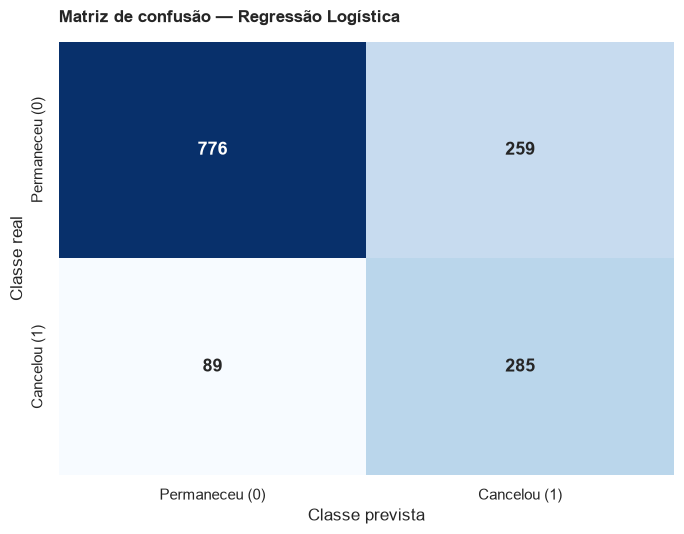

TN: 776 | FP: 259 | FN: 89 | TP: 285


In [8]:
cm = confusion_matrix(y_test, y_pred, labels=[NEGATIVE_LABEL, POSITIVE_LABEL])
tn, fp, fn, tp = cm.ravel()

fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    xticklabels=["Permaneceu (0)", "Cancelou (1)"],
    yticklabels=["Permaneceu (0)", "Cancelou (1)"],
    annot_kws={"size": 13, "weight": "bold"},
    ax=ax,
)
ax.set_title("Matriz de confusão — Regressão Logística", loc="left", weight="bold", pad=14)
ax.set_xlabel("Classe prevista")
ax.set_ylabel("Classe real")
fig.tight_layout()
plt.show()

print(f"TN: {tn:,} | FP: {fp:,} | FN: {fn:,} | TP: {tp:,}")

In [9]:
positive_support = int((y_test == POSITIVE_LABEL).sum())
predicted_positive = int((y_pred == POSITIVE_LABEL).sum())

print(
    f"Entre {positive_support:,} clientes que efetivamente cancelaram, "
    f"o modelo identificou {tp:,} e não identificou {fn:,}."
)
print(
    f"O modelo sinalizou {predicted_positive:,} clientes como churn; "
    f"{tp:,} eram cancelamentos reais e {fp:,} foram falsos positivos."
)

Entre 374 clientes que efetivamente cancelaram, o modelo identificou 285 e não identificou 89.
O modelo sinalizou 544 clientes como churn; 285 eram cancelamentos reais e 259 foram falsos positivos.


### 9.2 Curva ROC

A ROC-AUC mede a capacidade de ordenação do modelo entre positivos e negativos ao longo de diferentes thresholds. Ela não avalia, isoladamente, a calibração das probabilidades nem define o limiar operacional adequado.

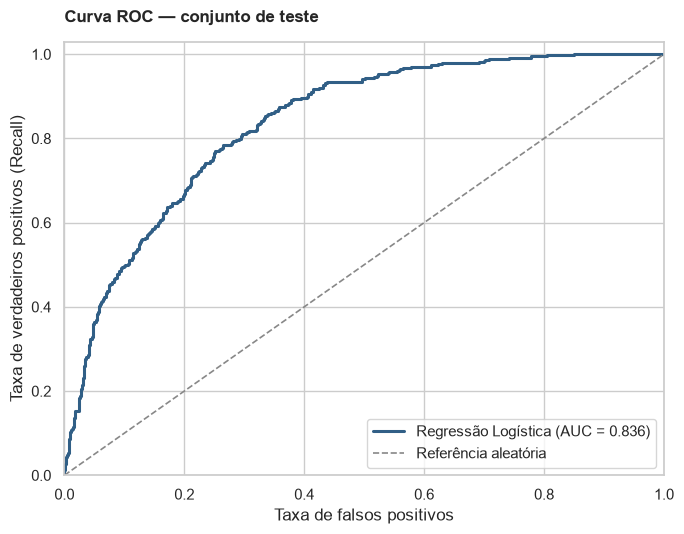

In [10]:
fpr, tpr, roc_thresholds = roc_curve(y_test, y_score, pos_label=POSITIVE_LABEL)
roc_auc = metrics["roc_auc"]

fig, ax = plt.subplots(figsize=(7, 5.5))
ax.plot(fpr, tpr, lw=2.2, color="#315F86", label=f"Regressão Logística (AUC = {roc_auc:.3f})")
ax.plot([0, 1], [0, 1], linestyle="--", color="#888888", lw=1.2, label="Referência aleatória")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.03)
ax.set_xlabel("Taxa de falsos positivos")
ax.set_ylabel("Taxa de verdadeiros positivos (Recall)")
ax.set_title("Curva ROC — conjunto de teste", loc="left", weight="bold", pad=14)
ax.legend(loc="lower right", frameon=True)
fig.tight_layout()
plt.show()

### 9.3 Curva Precision–Recall

A curva Precision–Recall é particularmente informativa quando a classe positiva é minoritária. A linha horizontal representa a prevalência de churn no conjunto de teste, isto é, o desempenho esperado de uma estratégia aleatória em termos de Average Precision.

Neste notebook, o valor reportado é **Average Precision (AP)**, calculado por `average_precision_score`. Ele resume a curva PR por uma média ponderada da precisão nos níveis de recall; não deve ser confundido automaticamente com a área trapezoidal de qualquer interpolação da curva.

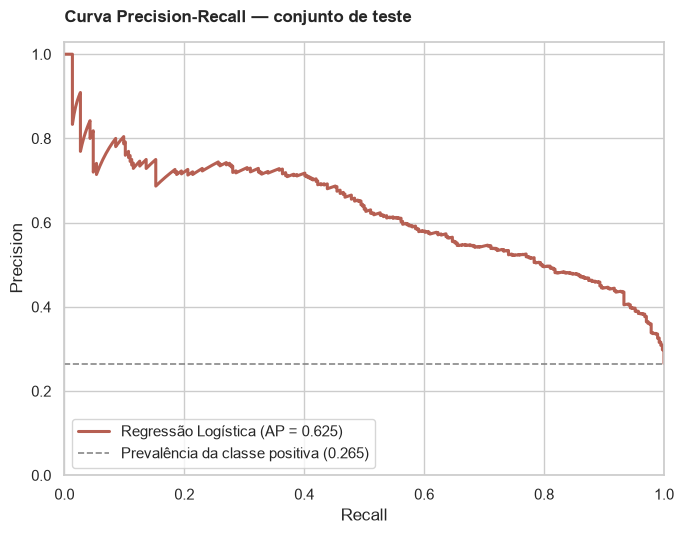

In [11]:
precision_values, recall_values, pr_thresholds = precision_recall_curve(
    y_test, y_score, pos_label=POSITIVE_LABEL
)
ap_score = metrics["average_precision"]
test_prevalence = float((y_test == POSITIVE_LABEL).mean())

fig, ax = plt.subplots(figsize=(7, 5.5))
ax.plot(
    recall_values,
    precision_values,
    lw=2.2,
    color="#B65F52",
    label=f"Regressão Logística (AP = {ap_score:.3f})",
)
ax.axhline(
    test_prevalence,
    linestyle="--",
    color="#888888",
    lw=1.2,
    label=f"Prevalência da classe positiva ({test_prevalence:.3f})",
)
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.03)
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("Curva Precision-Recall — conjunto de teste", loc="left", weight="bold", pad=14)
ax.legend(loc="lower left", frameon=True)
fig.tight_layout()
plt.show()

## 10. Interpretação dos resultados

A interpretação deve considerar o objetivo operacional. Em churn, falsos negativos podem significar perder a oportunidade de atuar sobre um cliente que cancelará; falsos positivos podem gerar contatos ou ofertas direcionadas a clientes que permaneceriam de qualquer maneira. O custo relativo desses erros não foi fornecido e, portanto, não é possível declarar um threshold ótimo neste estágio.

In [12]:
interpretation = f"""
### Síntese automática do baseline

- **Precision (classe churn): {metrics['precision']:.1%}** — entre os clientes sinalizados como churn, essa é a proporção que efetivamente cancelou.
- **Recall (classe churn): {metrics['recall']:.1%}** — essa é a proporção dos cancelamentos reais identificada pelo modelo.
- **F1-score: {metrics['f1_score']:.3f}** — síntese do equilíbrio entre Precision e Recall no threshold padrão.
- **ROC-AUC: {metrics['roc_auc']:.3f}** — capacidade de discriminação baseada no ranking dos scores.
- **Average Precision: {metrics['average_precision']:.3f}** — resumo da curva Precision–Recall; referência aleatória no teste: {test_prevalence:.3f}.

Na matriz de confusão, o modelo produziu **{fp:,} falsos positivos** e **{fn:,} falsos negativos**. A decisão de privilegiar maior Recall ou maior Precision depende do custo operacional de cada tipo de erro e deverá ser tratada em uma etapa específica de seleção de threshold.
"""
display(__import__("IPython").display.Markdown(interpretation))


### Síntese automática do baseline

- **Precision (classe churn): 52.4%** — entre os clientes sinalizados como churn, essa é a proporção que efetivamente cancelou.
- **Recall (classe churn): 76.2%** — essa é a proporção dos cancelamentos reais identificada pelo modelo.
- **F1-score: 0.621** — síntese do equilíbrio entre Precision e Recall no threshold padrão.
- **ROC-AUC: 0.836** — capacidade de discriminação baseada no ranking dos scores.
- **Average Precision: 0.625** — resumo da curva Precision–Recall; referência aleatória no teste: 0.265.

Na matriz de confusão, o modelo produziu **259 falsos positivos** e **89 falsos negativos**. A decisão de privilegiar maior Recall ou maior Precision depende do custo operacional de cada tipo de erro e deverá ser tratada em uma etapa específica de seleção de threshold.


## 11. Limitações e pontos de atenção

1. **Validação temporal:** a divisão aleatória não simula necessariamente a previsão de churn em períodos futuros. Para avaliar generalização temporal, serão necessários snapshots históricos e uma separação baseada no tempo.
2. **Threshold:** o limiar padrão de 0,50 é uma convenção do classificador, não uma decisão operacional otimizada.
3. **Ponderação de classes:** `class_weight="balanced"` altera o processo de ajuste; a qualidade das probabilidades deve ser examinada antes de utilizá-las como risco calibrado.


## 12. Conclusão

Este baseline estabelece uma referência reproduzível para classificação de churn, com pré-processamento encapsulado e avaliação no conjunto de teste. O resultado deve ser interpretado como ponto inicial de comparação, e não como modelo pronto para decisão operacional.

As próximas avaliações devem preservar a mesma definição de target e protocolo de divisão quando comparáveis, documentar alterações nas features e evitar utilizar repetidamente o conjunto de teste para orientar ajustes. Antes de qualquer uso prospectivo, a disponibilidade temporal dos atributos e uma validação temporal precisam ser demonstradas.

---

### Apêndice — configuração reproduzível

- Dataset: `telco_customer_churn.xlsx`
- Target: `Churn Value`
- Features: variáveis demográficas e geograficas, contratuais, de serviços e cobrança, após exclusões documentadas
- Modelo: `LogisticRegression(class_weight="balanced", max_iter=2000, random_state=42)`
- Divisão: 80% treino / 20% teste, estratificada
- Seed: 42
- Pré-processamento: mediana + indicador de ausência + StandardScaler para numéricas; moda + OneHotEncoder para categóricas